# T8 - EDA Seckin et al (Catalonia, Ghana_Nigeria, Iran_5 theo P1–P6)

### Khởi tạo đường dẫn EDA Seckin et al

In [19]:
import json
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent

CONFIG_PATH = PROJECT_ROOT / "configs" / "paths.json"

with open(CONFIG_PATH, "r", encoding="utf-8") as f: paths = json.load(f)

SECKIN_DIR = PROJECT_ROOT / paths["seckin_dir"]
T8_OUTPUT_DIR = PROJECT_ROOT / paths["t8_output_dir"]

assert SECKIN_DIR.is_dir(), f"Không tìm thấy dữ liệu: {SECKIN_DIR}"
T8_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("SECKIN_DIR   :", SECKIN_DIR)
print("T8_OUTPUT_DIR:", T8_OUTPUT_DIR)

PROJECT_ROOT : D:\Cpp\CN-24521602-ThangLH
SECKIN_DIR   : D:\Cpp\CN-24521602-ThangLH\data\Seckin
T8_OUTPUT_DIR: D:\Cpp\CN-24521602-ThangLH\reports\T8_EDA_Seckin


### Kiểm tra schema, kiểu dữ liệu, tỷ lệ thiếu theo nhãn và định dạng ID đã băm

In [20]:
import pandas as pd
import numpy as np
from IPython.display import display

CAMPAIGN_FILES = {
    "Catalonia": sorted(SECKIN_DIR.glob("Catalonia_part_*.parquet")),
    "Ghana_Nigeria": sorted(SECKIN_DIR.glob("Ghana_Nigeria_part_*.parquet")),
    "Iran_5": sorted(SECKIN_DIR.glob("Iran_5.gzip.parquet")),
}

ARRAY_COLS = ["hashtags", "urls", "account_mentions"]

ID_COLS = ["postid", "in_reply_to_postid", "in_reply_to_accountid", "accountid", "reposted_accountid", "reposted_postid"]

schema_results = {}
missing_results = {}
id_results = {}

def is_missing(value):
    if isinstance(value, (list, tuple, np.ndarray, dict)):
        return False
    return bool(pd.isna(value))

def inspect_campaign(campaign, files):
    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

    schema_rows = []
    for col in df.columns:
        s = df[col]
        missing_mask = s.map(is_missing)

        if col in ARRAY_COLS:
            unique_count = np.nan
        else:
            unique_count = s.nunique(dropna=True)

        schema_rows.append({"Trường dữ liệu": col, "Kiểu dữ liệu": str(s.dtype), "Số giá trị thiếu": int(missing_mask.sum()), "Số giá trị duy nhất": unique_count,})

    schema = pd.DataFrame(schema_rows)

    # Missing values theo IO / Control
    missing_rows = []

    for col in df.columns:
        row = {"Trường dữ liệu": col}

        for is_control, label in [(False, "IO"), (True, "Control")]:
            s = df.loc[df["is_control"] == is_control, col]
            missing_mask = s.map(is_missing)

            row[f"Thiếu {label} (n)"] = int(missing_mask.sum())
            row[f"Thiếu {label} (%)"] = round(
                100 * missing_mask.mean(), 2
            ) if len(s) else np.nan

            if col in ARRAY_COLS:
                row[f"Mảng rỗng {label} (%)"] = round(
                    100 * s.map(
                        lambda x: isinstance(
                            x, (list, tuple, np.ndarray)
                        ) and len(x) == 0
                    ).mean(), 2
                ) if len(s) else np.nan

        missing_rows.append(row)

    missing = pd.DataFrame(missing_rows)

    # Định dạng ID
    id_rows = []

    for col in ID_COLS:
        s = df[col].dropna().astype("string")
        lengths = s.str.len()

        id_rows.append({
            "Trường ID": col,
            "Kiểu dữ liệu": str(df[col].dtype),
            "Số ID duy nhất": s.nunique(),
            "Độ dài min": lengths.min() if len(s) else np.nan,
            "Độ dài max": lengths.max() if len(s) else np.nan,
            "Chỉ chứa chữ số (%)": round(
                100 * s.str.fullmatch(r"[0-9]+").mean(), 2
            ) if len(s) else np.nan,
            "Chỉ chứa hex (%)": round(
                100 * s.str.fullmatch(r"[0-9a-fA-F]+").mean(), 2
            ) if len(s) else np.nan,
        })

    ids = pd.DataFrame(id_rows)

    return len(df), schema, missing, ids

for campaign, files in CAMPAIGN_FILES.items():
    n_rows, schema, missing, ids = inspect_campaign(campaign, files)

    schema_results[campaign] = schema
    missing_results[campaign] = missing
    id_results[campaign] = ids

    print(f"\n{'=' * 65}")
    print(f"CHIẾN DỊCH: {campaign}")
    print(f"{'=' * 65}")
    print(f"Số file: {len(files)} | Số bài: {n_rows:,}")
    print(f"Số trường: {len(schema)}")

    print("\n1. SCHEMA VÀ KIỂU DỮ LIỆU")
    display(schema)

    print("\n2. TỶ LỆ THIẾU THEO NHÃN")
    display(missing)

    print("\n3. ĐỊNH DẠNG ID")
    display(ids)


CHIẾN DỊCH: Catalonia
Số file: 3 | Số bài: 125,009
Số trường: 19

1. SCHEMA VÀ KIỂU DỮ LIỆU


,Trường dữ liệu,Kiểu dữ liệu,Số giá trị thiếu,Số giá trị duy nhất
0,postid,str,0,125007.0
1,post_text,str,0,110881.0
2,application_name,str,0,111.0
3,post_language,str,29,44.0
4,in_reply_to_postid,str,113268,11072.0
5,in_reply_to_accountid,str,114362,4508.0
6,post_time,datetime64[us],0,119689.0
7,accountid,str,0,2683.0
8,account_profile_description,str,29031,2059.0
9,follower_count,int64,0,1761.0



2. TỶ LỆ THIẾU THEO NHÃN


,Trường dữ liệu,Thiếu IO (n),Thiếu IO (%),Thiếu Control (n),Thiếu Control (%),Mảng rỗng IO (%),Mảng rỗng Control (%)
0,postid,0,0.00,0,0.00,NaN,NaN
1,post_text,0,0.00,0,0.00,NaN,NaN
2,application_name,0,0.00,0,0.00,NaN,NaN
3,post_language,29,0.31,0,0.00,NaN,NaN
4,in_reply_to_postid,7288,76.80,105980,91.74,NaN,NaN
5,in_reply_to_accountid,7297,76.90,107065,92.68,NaN,NaN
6,post_time,0,0.00,0,0.00,NaN,NaN
7,accountid,0,0.00,0,0.00,NaN,NaN
8,account_profile_description,482,5.08,28549,24.71,NaN,NaN
9,follower_count,0,0.00,0,0.00,NaN,NaN



3. ĐỊNH DẠNG ID


,Trường ID,Kiểu dữ liệu,Số ID duy nhất,Độ dài min,Độ dài max,Chỉ chứa chữ số (%),Chỉ chứa hex (%)
0,postid,str,125007,42,42,0.0,100.0
1,in_reply_to_postid,str,11072,42,42,0.0,100.0
2,in_reply_to_accountid,str,4508,42,42,0.0,100.0
3,accountid,str,2683,42,42,0.0,100.0
4,reposted_accountid,str,23534,42,42,0.0,100.0
5,reposted_postid,str,87846,42,42,0.0,100.0


... (8 outputs left out)


2. TỶ LỆ THIẾU THEO NHÃN


,Trường dữ liệu,Thiếu IO (n),Thiếu IO (%),Thiếu Control (n),Thiếu Control (%),Mảng rỗng IO (%),Mảng rỗng Control (%)
0,postid,0,0.00,0,0.00,NaN,NaN
1,post_text,0,0.00,0,0.00,NaN,NaN
2,application_name,0,0.00,0,0.00,NaN,NaN
3,post_language,0,0.00,0,0.00,NaN,NaN
4,in_reply_to_postid,1787,72.94,37249,86.72,NaN,NaN
5,in_reply_to_accountid,1788,72.98,38009,88.49,NaN,NaN
6,post_time,0,0.00,0,0.00,NaN,NaN
7,accountid,0,0.00,0,0.00,NaN,NaN
8,account_profile_description,15,0.61,8413,19.59,NaN,NaN
9,follower_count,0,0.00,0,0.00,NaN,NaN



3. ĐỊNH DẠNG ID


,Trường ID,Kiểu dữ liệu,Số ID duy nhất,Độ dài min,Độ dài max,Chỉ chứa chữ số (%),Chỉ chứa hex (%)
0,postid,str,45403,42,42,0.0,100.0
1,in_reply_to_postid,str,6091,42,42,0.0,100.0
2,in_reply_to_accountid,str,3800,42,42,0.0,100.0
3,accountid,str,1351,42,42,0.0,100.0
4,reposted_accountid,str,17674,42,42,0.0,100.0
5,reposted_postid,str,29259,42,42,0.0,100.0


### Thống kê tổng quan IO và Control cho từng chiến dịch

In [21]:
import pandas as pd
import numpy as np
from IPython.display import display

CAMPAIGN_FILES = {
    "Catalonia": sorted(SECKIN_DIR.glob("Catalonia_part_*.parquet")),
    "Ghana_Nigeria": sorted(SECKIN_DIR.glob("Ghana_Nigeria_part_*.parquet")),
    "Iran_5": sorted(SECKIN_DIR.glob("Iran_5.gzip.parquet")),
}

summary_results = {}

def summarize_campaign(campaign, files):
    cols = ["accountid", "post_time", "is_control", "is_repost", "reposted_postid"]
    df = pd.concat([pd.read_parquet(f, columns=cols) for f in files], ignore_index=True)
    df["post_time"] = pd.to_datetime(df["post_time"], utc=True, errors="raise")
    results = {}

    for is_control, label in [(False, "IO"), (True, "Control")]:
        sub = df[df["is_control"] == is_control].copy()

        posts_per_account = sub.groupby("accountid").size()
        reposts = sub[sub["is_repost"] & sub["reposted_postid"].notna() & sub["reposted_postid"].ne("")].copy()
        reposts = reposts.sort_values(["reposted_postid", "post_time"], kind="stable")
        delta = (reposts.groupby("reposted_postid")["post_time"].diff().dt.total_seconds().dropna())

        results[label] = {
            "Số bài": len(sub),
            "Số tài khoản": sub["accountid"].nunique(),
            "Khoảng thời gian": (f"{sub['post_time'].min():%d/%m/%Y} "f"{sub['post_time'].max():%d/%m/%Y}"),
            "Số ngày có hoạt động": (sub["post_time"].dt.floor("D").nunique()),
            "Bài/tài khoản (trung vị; lớn nhất)": (
                f"{posts_per_account.median():g}; "
                f"{posts_per_account.max():,}"),
            "Tỷ lệ timestamp có giây = 0": (100 * ((sub["post_time"].dt.second == 0) & (sub["post_time"].dt.microsecond == 0)).mean() ),
            "Tỷ lệ repost": (100 * sub["is_repost"].mean()),
            "Cặp repost liên tiếp cùng bài có Δt = 0 giây": (100 * (delta == 0).mean() if len(delta) else np.nan),
        }

    summary = pd.DataFrame(results)
    summary.index.name = "Chỉ số"

    for metric in ["Số bài", "Số tài khoản", "Số ngày có hoạt động",]:
        summary.loc[metric] = summary.loc[metric].map(
            lambda x: f"{x:,}"
        )

    for metric in ["Tỷ lệ timestamp có giây = 0", "Tỷ lệ repost", "Cặp repost liên tiếp cùng bài có Δt = 0 giây",
    ]:
        summary.loc[metric] = summary.loc[metric].map(
            lambda x: f"{x:.2f}%" if pd.notna(x) else "N/A"
        )

    return summary

file_summary_results = {}

for campaign, files in CAMPAIGN_FILES.items():
    for file_path in files:

        file_name = file_path.name
        summary = summarize_campaign(campaign=campaign, files=[file_path])
        file_summary_results[file_name] = summary

        print(f"\n{'=' * 75}")
        print(f"CHIẾN DỊCH : {campaign}")
        print(f"FILE       : {file_name}")
        print(f"{'=' * 75}")
        display(summary)


CHIẾN DỊCH : Catalonia
FILE       : Catalonia_part_1.gzip.parquet


,IO,Control
Chỉ số,,
Số bài,"3,789","46,211"
Số tài khoản,21,"1,086"
Khoảng thời gian,24/11/2011 22/02/2018,24/11/2011 22/02/2018
Số ngày có hoạt động,485,319
Bài/tài khoản (trung vị; lớn nhất),"72; 1,132",25; 372
Tỷ lệ timestamp có giây = 0,100.00%,1.70%
Tỷ lệ repost,74.85%,83.29%
Cặp repost liên tiếp cùng bài có Δt = 0 giây,83.26%,0.17%



CHIẾN DỊCH : Catalonia
FILE       : Catalonia_part_2.gzip.parquet


,IO,Control
Chỉ số,,
Số bài,"3,999","46,001"
Số tài khoản,30,"1,082"
Khoảng thời gian,23/02/2018 09/11/2018,22/02/2018 09/11/2018
Số ngày có hoạt động,228,144
Bài/tài khoản (trung vị; lớn nhất),70; 802,25; 396
Tỷ lệ timestamp có giây = 0,100.00%,2.00%
Tỷ lệ repost,51.86%,80.81%
Cặp repost liên tiếp cùng bài có Δt = 0 giây,57.59%,0.07%



CHIẾN DỊCH : Catalonia
FILE       : Catalonia_part_3.gzip.parquet


,IO,Control
Chỉ số,,
Số bài,"1,701","23,308"
Số tài khoản,75,574
Khoảng thời gian,10/11/2018 24/01/2019,09/11/2018 24/01/2019
Số ngày có hoạt động,66,45
Bài/tài khoản (trung vị; lớn nhất),6; 257,24.5; 327
Tỷ lệ timestamp có giây = 0,100.00%,1.78%
Tỷ lệ repost,69.72%,84.85%
Cặp repost liên tiếp cùng bài có Δt = 0 giây,46.47%,0.05%


... (2 outputs left out)


CHIẾN DỊCH : Ghana_Nigeria
FILE       : Ghana_Nigeria_part_2.gzip.parquet


,IO,Control
Chỉ số,,
Số bài,"19,804","13,605"
Số tài khoản,48,326
Khoảng thời gian,01/11/2019 29/02/2020,02/11/2019 29/02/2020
Số ngày có hoạt động,121,27
Bài/tài khoản (trung vị; lớn nhất),"201.5; 4,449",26; 198
Tỷ lệ timestamp có giây = 0,100.00%,1.60%
Tỷ lệ repost,42.22%,73.98%
Cặp repost liên tiếp cùng bài có Δt = 0 giây,9.31%,1.37%



CHIẾN DỊCH : Iran_5
FILE       : Iran_5.gzip.parquet


,IO,Control
Chỉ số,,
Số bài,"2,450","42,955"
Số tài khoản,104,"1,247"
Khoảng thời gian,08/01/2020 01/07/2020,11/01/2020 01/07/2020
Số ngày có hoạt động,91,43
Bài/tài khoản (trung vị; lớn nhất),2; 433,17; 198
Tỷ lệ timestamp có giây = 0,100.00%,2.49%
Tỷ lệ repost,22.49%,72.16%
Cặp repost liên tiếp cùng bài có Δt = 0 giây,17.80%,0.40%


### Thống kê đối chiếu Bảng 1 của Seckin et al. (2025)

In [22]:
import pandas as pd
import numpy as np
from IPython.display import display

def count_items(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return sum(
            pd.notna(x) and str(x).strip() != ""
            for x in value
        )
    return 0

def count_unique_items(series):
    unique_values = set()

    for value in series:
        if isinstance(value, (list, tuple, np.ndarray)):
            for item in value:
                if item is not None and not pd.isna(item):
                    item = str(item).strip()
                    if item:
                        unique_values.add(item)

    return len(unique_values)


def summarize_group(df, campaign, label):
    years = df["post_time"].dt.year.dropna()

    return {
        "Campaign": campaign,
        "Group": label,
        "Year": (
            f"{int(years.min())}–{int(years.max())}"
            if not years.empty else "N/A"
        ),
        "Accounts": df["accountid"].nunique(),
        "Posts": len(df),
        "Reposts": int(df["is_repost"].sum()),
        "Replies": int(df["in_reply_to_postid"].notna().sum()),
        "Hashtags": count_unique_items(df["hashtags"]),
        "URLs": count_unique_items(df["urls"]),
        "Mentions": count_unique_items(df["account_mentions"])
    }

table1_rows = []

for campaign, files in CAMPAIGN_FILES.items():
    if not files:
        raise FileNotFoundError(f"Không tìm thấy file: {campaign}")

    df = pd.concat([pd.read_parquet(f) for f in files],ignore_index=True)
    df["post_time"] = pd.to_datetime(df["post_time"], utc=True)
    table1_rows.append(summarize_group(df[df["is_control"] == False],campaign, "IO"))

    table1_rows.append(summarize_group(df[df["is_control"] == True],campaign, "Control"))
    table1_rows.append(summarize_group(df, campaign, "Total"))

table1_summary = pd.DataFrame(table1_rows)

display(table1_summary)


,Campaign,Group,Year,Accounts,Posts,Reposts,Replies,Hashtags,URLs,Mentions
0,Catalonia,IO,2011–2019,76,9489,6096,2201,699,2226,2260
1,Catalonia,Control,2011–2019,2607,115520,95436,9540,25049,75634,39974
2,Catalonia,Total,2011–2019,2683,125009,101532,11741,25279,77782,40754
3,Ghana_Nigeria,IO,2014–2020,60,39964,16310,8697,8340,15130,11168
4,Ghana_Nigeria,Control,2014–2020,1166,43445,30304,4995,15247,29345,28054
5,Ghana_Nigeria,Total,2014–2020,1226,83409,46614,13692,21850,44450,37601
6,Iran_5,IO,2020–2020,104,2450,551,663,148,1166,1024
7,Iran_5,Control,2020–2020,1247,42955,30996,5706,14280,27725,28314
8,Iran_5,Total,2020–2020,1351,45405,31547,6369,14358,28889,29199


### P1: Hài hòa độ phân giải thời gian

In [23]:
import pandas as pd
from IPython.display import display

p1_data = {}
p1_results = {}

for campaign, files_of_campaign in CAMPAIGN_FILES.items():
    df = pd.concat([pd.read_parquet(f) for f in files_of_campaign],ignore_index=True)

    df["post_time"] = pd.to_datetime(df["post_time"], utc=True, errors="raise")

    df["t_min"] = df["post_time"].dt.floor("min")

    after = df.groupby("is_control")["t_min"].apply(lambda t: ((t.dt.second == 0) & (t.dt.microsecond == 0) & (t.dt.nanosecond == 0)).mean() * 100)

    result = pd.DataFrame({"Sau P1 (%)": after})

    result.index = result.index.map({False: "IO", True: "Control"})
    result.index.name = "Nhãn"

    assert df["t_min"].notna().all(), (f"{campaign}: Có timestamp thiếu sau P1")
    assert (after == 100).all(), (f"{campaign}: P1 chưa đạt 100%")

    p1_data[campaign] = df
    p1_results[campaign] = result

    print(f"\n{'=' * 65}")
    print(f"CHIẾN DỊCH: {campaign}")
    print(f"{'=' * 65}")

    display(result)


CHIẾN DỊCH: Catalonia


,Sau P1 (%)
Nhãn,
IO,100.0
Control,100.0



CHIẾN DỊCH: Ghana_Nigeria


,Sau P1 (%)
Nhãn,
IO,100.0
Control,100.0



CHIẾN DỊCH: Iran_5


,Sau P1 (%)
Nhãn,
IO,100.0
Control,100.0


### P2: Bảng phủ theo ngày (Daily Coverage)

In [24]:
import pandas as pd
from IPython.display import display

M_IO = 2
C_CTRL = 20
GAP = 3  

p2_data = {}
p2_coverage = {}
p2_covered_days = {}

for campaign, df_p1 in p1_data.items():
    df = df_p1.copy()
    df["day"] = df["t_min"].dt.floor("D")
    cov = (df.groupby(["day", "is_control"])["accountid"].nunique().unstack(fill_value=0).rename(columns={False: "io", True: "ctrl"}).reindex(columns=["io", "ctrl"], fill_value=0))

    post_counts = (df.groupby(["day", "is_control"]).size().unstack(fill_value=0).rename(columns={False: "posts_io", True: "posts_ctrl"}).reindex(columns=["posts_io", "posts_ctrl"],fill_value=0))

    cov = cov.join(post_counts)
    cov["total_posts"] = cov["posts_io"] + cov["posts_ctrl"]
    cov["covered"] = ((cov["io"] >= M_IO) & (cov["ctrl"] >= C_CTRL))

    covered = cov.index[cov["covered"]]

    p2_data[campaign] = df
    p2_coverage[campaign] = cov
    p2_covered_days[campaign] = covered

    print(f"\n{'=' * 75}")
    print(f"CHIẾN DỊCH: {campaign}")
    print(f"{'=' * 75}")

    print(f"Tổng số ngày có hoạt động : {len(cov):,}")
    print(f"Số ngày được phủ          : {len(covered):,}")
    print(f"Số ngày không được phủ    : {(~cov['covered']).sum():,}")
    print(f"Tỷ lệ ngày được phủ       : {cov['covered'].mean():.2%}")
    print(f"Ngưỡng: IO >= {M_IO}, Control >= {C_CTRL}")

    display(cov)

    T8_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for campaign, cov in p2_coverage.items(): output_path = T8_OUTPUT_DIR / f"P2_coverage_{campaign}.csv"
    cov.to_csv( output_path, index=True, index_label="day", encoding="utf-8-sig")


CHIẾN DỊCH: Catalonia
Tổng số ngày có hoạt động : 779
Số ngày được phủ          : 19
Số ngày không được phủ    : 760
Tỷ lệ ngày được phủ       : 2.44%
Ngưỡng: IO >= 2, Control >= 20


is_control,io,ctrl,posts_io,posts_ctrl,total_posts,covered
day,,,,,,
2011-11-24 00:00:00+00:00,1,1,1,43,44,False
2011-11-25 00:00:00+00:00,1,1,1,24,25,False
2011-11-30 00:00:00+00:00,1,0,1,0,1,False
2011-12-13 00:00:00+00:00,1,0,2,0,2,False
2011-12-16 00:00:00+00:00,1,0,1,0,1,False
...,...,...,...,...,...,...
2019-01-19 00:00:00+00:00,1,0,1,0,1,False
2019-01-21 00:00:00+00:00,5,5,23,203,226,False
2019-01-22 00:00:00+00:00,6,6,16,351,367,False



CHIẾN DỊCH: Ghana_Nigeria
Tổng số ngày có hoạt động : 976
Số ngày được phủ          : 2
Số ngày không được phủ    : 974
Tỷ lệ ngày được phủ       : 0.20%
Ngưỡng: IO >= 2, Control >= 20


is_control,io,ctrl,posts_io,posts_ctrl,total_posts,covered
day,,,,,,
2014-04-04 00:00:00+00:00,1,1,9,29,38,False
2014-04-06 00:00:00+00:00,1,0,1,0,1,False
2014-04-09 00:00:00+00:00,1,0,1,0,1,False
2014-04-20 00:00:00+00:00,1,0,2,0,2,False
2014-04-21 00:00:00+00:00,1,0,13,0,13,False
...,...,...,...,...,...,...
2020-02-25 00:00:00+00:00,10,0,261,0,261,False
2020-02-26 00:00:00+00:00,9,0,229,0,229,False
2020-02-27 00:00:00+00:00,9,0,236,0,236,False



CHIẾN DỊCH: Iran_5
Tổng số ngày có hoạt động : 91
Số ngày được phủ          : 39
Số ngày không được phủ    : 52
Tỷ lệ ngày được phủ       : 42.86%
Ngưỡng: IO >= 2, Control >= 20


is_control,io,ctrl,posts_io,posts_ctrl,total_posts,covered
day,,,,,,
2020-01-08 00:00:00+00:00,5,0,15,0,15,False
2020-01-11 00:00:00+00:00,11,21,29,531,560,True
2020-01-13 00:00:00+00:00,14,0,14,0,14,False
2020-01-14 00:00:00+00:00,14,24,96,538,634,True
2020-01-15 00:00:00+00:00,14,24,41,943,984,True
...,...,...,...,...,...,...
2020-06-27 00:00:00+00:00,12,22,12,622,634,True
2020-06-28 00:00:00+00:00,12,0,12,0,12,False
2020-06-29 00:00:00+00:00,12,22,25,1187,1212,True


### P3: Xác định cửa sổ đánh giá (Evaluation Window)

In [25]:
import pandas as pd
from IPython.display import display

# Ngưỡng đã chốt từ P2: M_IO = 2, C_CTRL = 20, GAP = 3

p3_data = {}
p3_windows = {}
p3_summary_rows = []

for campaign, df in p2_data.items():

    cov = p2_coverage[campaign]
    covered = cov.index[(cov["io"] >= M_IO) & (cov["ctrl"] >= C_CTRL)].sort_values()

    if len(covered) == 0:
        print(f"{campaign}: Không có ngày được phủ.")
        continue

    gaps = covered.to_series().diff().dt.days.fillna(1)
    seg_id = (gaps > GAP + 1).cumsum()

    seg = covered.to_series().groupby(seg_id.values).agg(["min", "max", "count"])

    seg["duration_days"] = (seg["max"] - seg["min"]).dt.days + 1

    win = seg.sort_values("duration_days", ascending=False).iloc[0]

    df_win = df[(df["day"] >= win["min"]) &(df["day"] <= win["max"])].copy()

    p3_data[campaign] = df_win
    p3_windows[campaign] = (win["min"], win["max"])

    io_all = df[~df["is_control"]]
    io_win = df_win[~df_win["is_control"]]
    ctrl_win = df_win[df_win["is_control"]]

    p3_summary_rows.append({
        "campaign": campaign,
        "start": win["min"],
        "end": win["max"],
        "duration_days": int(win["duration_days"]),
        "io_actions_retained_pct": (100 * len(io_win) / len(io_all)if len(io_all) else 0),
        "io_accounts": io_win["accountid"].nunique(),
        "control_accounts": ctrl_win["accountid"].nunique()
    })

p3_report = pd.DataFrame(p3_summary_rows)
display(p3_report)

output_path = T8_OUTPUT_DIR / "P3_window_report.csv"
p3_report.to_csv(output_path, index=False,encoding="utf-8-sig")

,campaign,start,end,duration_days,io_actions_retained_pct,io_accounts,control_accounts
0,Catalonia,2019-01-02 00:00:00+00:00,2019-01-10 00:00:00+00:00,9,4.542101,62,168
1,Ghana_Nigeria,2019-12-01 00:00:00+00:00,2019-12-01 00:00:00+00:00,1,0.355320,20,20
2,Iran_5,2020-05-27 00:00:00+00:00,2020-06-09 00:00:00+00:00,14,30.734694,103,344


### P4: Xác định mốc đánh giá (Evaluation Checkpoints)

In [26]:
import pandas as pd
from IPython.display import display

IO_RATIOS = [5, 10, 25, 50, 75, 100]
DAY_OFFSETS = [1, 3, 7, 14, 30]

p4_results = {}

for campaign, df in p3_data.items():

    if df.empty:
        print(f"{campaign}: Không có dữ liệu trong cửa sổ P3.")
        continue

    start, end = p3_windows[campaign]
    df = df.sort_values("t_min").copy()
    io = df[~df["is_control"]]

    if io.empty:
        print(f"{campaign}: Không có hành động IO.")
        continue

    checkpoints = []

    # Mốc theo tỷ lệ số hành động IO trong cửa sổ
    io_times = io["t_min"].sort_values().reset_index(drop=True)

    for pct in IO_RATIOS:
        n = max(1, (len(io_times) * pct + 99) // 100)
        tau = io_times.iloc[n - 1]

        checkpoints.append({"checkpoint_type": "io_ratio", "checkpoint": f"{pct}%", "tau": tau})

    # Mốc theo ngày từ đầu cửa sổ P3
    # Ngày 1 kết thúc lúc 23:59:59 UTC của ngày bắt đầu
    for day in DAY_OFFSETS:
        tau = start + pd.Timedelta(days=day) - pd.Timedelta(minutes=1)

        if tau > end + pd.Timedelta(days=1) - pd.Timedelta(minutes=1):
            continue

        checkpoints.append({"checkpoint_type": "day","checkpoint": f"Day {day}","tau": tau})

    rows = []

    for cp in checkpoints:
        df_tau = df[df["t_min"] <= cp["tau"]]

        rows.append({"campaign": campaign, "checkpoint_type": cp["checkpoint_type"], "checkpoint": cp["checkpoint"], "tau": cp["tau"], "io_accounts": df_tau.loc[
                ~df_tau["is_control"], "accountid"].nunique(), "control_accounts": df_tau.loc[df_tau["is_control"], "accountid"].nunique()})

    result = pd.DataFrame(rows)
    p4_results[campaign] = result

    print(f"\n{'=' * 70}")
    print(f"CHIẾN DỊCH: {campaign}")
    print(f"{'=' * 70}")
    display(result)


CHIẾN DỊCH: Catalonia


,campaign,checkpoint_type,checkpoint,tau,io_accounts,control_accounts
0,Catalonia,io_ratio,5%,2019-01-02 09:11:00+00:00,1,9
1,Catalonia,io_ratio,10%,2019-01-02 09:17:00+00:00,1,9
2,Catalonia,io_ratio,25%,2019-01-02 10:16:00+00:00,14,10
3,Catalonia,io_ratio,50%,2019-01-06 21:05:00+00:00,42,59
4,Catalonia,io_ratio,75%,2019-01-08 13:00:00+00:00,57,101
5,Catalonia,io_ratio,100%,2019-01-10 17:07:00+00:00,62,158
6,Catalonia,day,Day 1,2019-01-02 23:59:00+00:00,22,22
7,Catalonia,day,Day 3,2019-01-04 23:59:00+00:00,42,59
8,Catalonia,day,Day 7,2019-01-08 23:59:00+00:00,57,107



CHIẾN DỊCH: Ghana_Nigeria


,campaign,checkpoint_type,checkpoint,tau,io_accounts,control_accounts
0,Ghana_Nigeria,io_ratio,5%,2019-12-01 02:59:00+00:00,3,11
1,Ghana_Nigeria,io_ratio,10%,2019-12-01 05:51:00+00:00,5,14
2,Ghana_Nigeria,io_ratio,25%,2019-12-01 06:58:00+00:00,6,15
3,Ghana_Nigeria,io_ratio,50%,2019-12-01 12:54:00+00:00,11,16
4,Ghana_Nigeria,io_ratio,75%,2019-12-01 16:57:00+00:00,15,16
5,Ghana_Nigeria,io_ratio,100%,2019-12-01 23:30:00+00:00,20,18
6,Ghana_Nigeria,day,Day 1,2019-12-01 23:59:00+00:00,20,20



CHIẾN DỊCH: Iran_5


,campaign,checkpoint_type,checkpoint,tau,io_accounts,control_accounts
0,Iran_5,io_ratio,5%,2020-05-28 06:22:00+00:00,22,46
1,Iran_5,io_ratio,10%,2020-05-31 10:07:00+00:00,22,95
2,Iran_5,io_ratio,25%,2020-06-03 17:27:00+00:00,49,219
3,Iran_5,io_ratio,50%,2020-06-07 12:21:00+00:00,103,284
4,Iran_5,io_ratio,75%,2020-06-08 09:31:00+00:00,103,300
5,Iran_5,io_ratio,100%,2020-06-09 13:20:00+00:00,103,339
6,Iran_5,day,Day 1,2020-05-27 23:59:00+00:00,22,32
7,Iran_5,day,Day 3,2020-05-29 23:59:00+00:00,22,64
8,Iran_5,day,Day 7,2020-06-02 23:59:00+00:00,25,162
9,Iran_5,day,Day 14,2020-06-09 23:59:00+00:00,103,344


### P5: Baseline tầm thường (Trivial Baselines)

In [27]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from IPython.display import display

p5_results = []
p5_delta_results = []

def evaluate_auc(y, score):
    if y.nunique() < 2:
        return np.nan
    return roc_auc_score(y, score)


def zero_delta_ratio(df, time_col):
    reposts = df[df["is_repost"] & df["reposted_postid"].notna() & df["reposted_postid"].ne("")].copy()

    if reposts.empty:
        return pd.Series(dtype=float), pd.DataFrame()

    # Số tài khoản khác nhau repost cùng bài, cùng thời điểm
    n_accounts = (reposts.groupby(["reposted_postid", time_col])["accountid"].transform("nunique"))

    reposts["delta_zero"] = n_accounts >= 2

    # Tỷ lệ đồng repost Δt = 0 của từng tài khoản
    scores = (
        reposts.groupby("accountid")["delta_zero"]
        .mean()
    )
    return scores, reposts

for campaign, df_win in p3_data.items():

    if df_win.empty:
        print(f"{campaign}: Cửa sổ P3 rỗng, bỏ qua.")
        continue

    df = df_win.copy()

    # Baseline (i): Thời điểm xuất hiện + số hành động

    accounts = (df.groupby("accountid").agg(first_seen=("t_min", "min"),action_count=("postid", "size"),is_control=("is_control", "first")))

    assert (df.groupby("accountid")["is_control"].nunique() <= 1).all(), f"{campaign}: Tài khoản có nhãn mâu thuẫn"

    accounts["y_true"] = (~accounts["is_control"]).astype(int)
    accounts["time_score"] = (1 - accounts["first_seen"].rank(pct=True))
    accounts["volume_score"] = (accounts["action_count"].rank(pct=True))
    accounts["baseline_i"] = (accounts["time_score"] + accounts["volume_score"]) / 2

    auc_i = evaluate_auc(accounts["y_true"], accounts["baseline_i"])

    # Baseline (ii): Chỉ dùng tỷ lệ Δt = 0
    # Trước P1: timestamp gốc
    scores_before, reposts_before = zero_delta_ratio(df, "post_time")

    # Sau P1: timestamp đã làm tròn xuống phút
    scores_after, reposts_after = zero_delta_ratio(df, "t_min")

    # Tài khoản không có repost hợp lệ: điểm = 0
    accounts["zero_before"] = (scores_before.reindex(accounts.index).fillna(0))
    accounts["zero_after"] = (scores_after.reindex(accounts.index).fillna(0))

    auc_before = evaluate_auc(accounts["y_true"], accounts["zero_before"])
    auc_after = evaluate_auc(accounts["y_true"], accounts["zero_after"])

    p5_results.append({"campaign": campaign, "io_accounts": int(accounts["y_true"].sum()), "control_accounts": int((accounts["y_true"] == 0).sum()), "auc_baseline_i": auc_i,
        "auc_delta_before_p1": auc_before, "auc_delta_after_p1": auc_after, "auc_change_after_p1": auc_after - auc_before})

    # Tỷ lệ đồng repost Δt = 0 theo nhãn
    for stage, reposts in [("Before P1", reposts_before),("After P1", reposts_after)]:
        for is_control, label in [(False, "IO"),(True, "Control")]:
            sub = reposts[reposts["is_control"] == is_control]

            p5_delta_results.append({"campaign": campaign, "stage": stage, "label": label, "valid_reposts": len(sub), "delta_zero_pct": (100 * sub["delta_zero"].mean()
                if len(sub) else np.nan)})

p5_report = pd.DataFrame(p5_results)
p5_delta_report = pd.DataFrame(p5_delta_results)

print("P5 — KHẢ NĂNG PHÂN BIỆT IO / CONTROL (ROC-AUC)")
display(p5_report.round(4))

print("\nP5 — TỶ LỆ ĐỒNG REPOST Δt = 0 THEO NHÃN")
display(p5_delta_report.round(2))

T8_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

P5 — KHẢ NĂNG PHÂN BIỆT IO / CONTROL (ROC-AUC)


,campaign,io_accounts,control_accounts,auc_baseline_i,auc_delta_before_p1,auc_delta_after_p1,auc_change_after_p1
0,Catalonia,62,168,0.4513,0.9264,0.8876,-0.0388
1,Ghana_Nigeria,20,20,0.1575,0.5750,0.4050,-0.1700
2,Iran_5,103,344,0.2654,0.4971,0.4128,-0.0843



P5 — TỶ LỆ ĐỒNG REPOST Δt = 0 THEO NHÃN


,campaign,stage,label,valid_reposts,delta_zero_pct
0,Catalonia,Before P1,IO,340,38.24
1,Catalonia,Before P1,Control,4907,0.04
2,Catalonia,After P1,IO,340,38.24
3,Catalonia,After P1,Control,4907,0.84
4,Ghana_Nigeria,Before P1,IO,75,4.00
5,Ghana_Nigeria,Before P1,Control,738,0.00
6,Ghana_Nigeria,After P1,IO,75,4.00
7,Ghana_Nigeria,After P1,Control,738,1.08
8,Iran_5,Before P1,IO,0,NaN
9,Iran_5,Before P1,Control,7123,0.03


### P6: So sánh có/không có lớp hashtag và phân tích cụm Control

#### P6.1 — Khởi tạo, import module và cấu hình
Ở bước đầu, dùng β cố định cho các lớp để chạy kiểm tra ablation. Giá trị 1.0 là cấu hình thử nghiệm, chưa phải β tối ưu của Iannucci. Khi có β đã kiểm chứng, chỉ cần thay cấu hình này và chạy lại.

In [28]:
import sys
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.graph.time_aware import (prepare_action_pairs, build_layer_graph_from_pairs)
from src.community.leiden import detect_communities_multiplex
from src.eval.metrics import (best_community_f1, weighted_precision, clustering_homogeneity)

P6_LAYERS = ["retweet", "hashtag", "mention", "url"]
P6_VARIANTS = {
    "with_hashtag": P6_LAYERS,
    "without_hashtag": ["retweet", "mention", "url"]
}

# Cấu hình beta thử nghiệm, không phải beta tối ưu
P6_BETA = {"retweet": 1.0, "hashtag": 1.0, "mention": 1.0, "url": 1.0}
P6_SEEDS = [42]
T8_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert p3_data, "Chưa có dữ liệu P3"

print("P6 initialized")
print("Campaigns:", list(p3_data.keys()))
print("Layers:", P6_LAYERS)
print("Beta:", P6_BETA)
print("Seeds:", P6_SEEDS)
print("Output:", T8_OUTPUT_DIR)

P6 initialized
Campaigns: ['Catalonia', 'Ghana_Nigeria', 'Iran_5']
Layers: ['retweet', 'hashtag', 'mention', 'url']
Beta: {'retweet': 1.0, 'hashtag': 1.0, 'mention': 1.0, 'url': 1.0}
Seeds: [42]
Output: D:\Cpp\CN-24521602-ThangLH\reports\T8_EDA_Seckin


#### P6.2 — Chuyển dữ liệu Seckin thành hành động đa lớp
Mã T6 sử dụng cấu trúc (user_id, timestamp, action_type, content_id). Cell này chuyển bốn lớp retweet, hashtag, mention, URL sang định dạng đó. Timestamp được biểu diễn bằng số phút tính từ Unix epoch, phù hợp với phép chia delta_t / 1440 (đổi phút sang ngày) trong time_aware.py.

In [29]:
def extract_array_items(value):
    if not isinstance(value, (list, tuple, np.ndarray)):
        return []

    return [
        str(item).strip()
        for item in value
        if isinstance(item, str) and item.strip()
    ]


def build_seckin_events(df):
    required = ["accountid", "t_min", "is_repost", "reposted_postid", "hashtags", "urls", "account_mentions"]

    missing = set(required) - set(df.columns)
    if missing:
        raise ValueError(f"Thiếu trường: {missing}")

    base = df.copy()

    if base["t_min"].isna().any():
        raise ValueError("Có timestamp thiếu sau P1")

    epoch = pd.Timestamp("1970-01-01", tz="UTC")
    base["timestamp"] = ((base["t_min"] - epoch).dt.total_seconds().floordiv(60).astype("int64"))
    events = []

    # 1. Retweet
    rt = base.loc[
        base["is_repost"]
        & base["reposted_postid"].notna()
        & base["reposted_postid"].ne(""),
        ["accountid", "timestamp", "reposted_postid"]
    ].rename(columns={
        "accountid": "user_id",
        "reposted_postid": "content_id"
    })

    rt["action_type"] = "retweet"
    events.append(rt)

    # 2. Hashtag, Mention, URL
    for col, layer in [
        ("hashtags", "hashtag"),
        ("account_mentions", "mention"),
        ("urls", "url")
    ]:
        part = base[["accountid", "timestamp", col]].copy()

        part[col] = part[col].map(extract_array_items)
        part = part.explode(col).dropna(subset=[col])
        part = part.rename(columns={"accountid": "user_id", col: "content_id"})
        part["action_type"] = layer
        events.append(part)
    result = pd.concat(events, ignore_index=True)
    result = result[["user_id", "timestamp", "action_type", "content_id"]]
    return result.sort_values(["timestamp", "action_type", "user_id"], kind="stable").reset_index(drop=True)


p6_events = {}
p6_ground_truth = {}
p6_action_rows = []

for campaign, df in p3_data.items():

    if df.empty:
        print(f"{campaign}: Không có dữ liệu P3")
        continue

    label_counts = df.groupby("accountid")["is_control"].nunique()
    assert (label_counts == 1).all(), (
        f"{campaign}: Tài khoản có nhãn không nhất quán"
    )

    labels = df.groupby("accountid")["is_control"].first()

    p6_ground_truth[campaign] = set(
        labels.index[labels == False]
    )

    actions = build_seckin_events(df)
    p6_events[campaign] = actions

    for layer in P6_LAYERS:
        sub = actions[actions["action_type"] == layer]

        p6_action_rows.append({
            "campaign": campaign,
            "layer": layer,
            "actions": len(sub),
            "accounts": sub["user_id"].nunique(),
            "unique_contents": sub["content_id"].nunique()
        })

p6_action_summary = pd.DataFrame(p6_action_rows)

print("P6 — SỐ HÀNH ĐỘNG THEO LỚP")
display(p6_action_summary)

P6 — SỐ HÀNH ĐỘNG THEO LỚP


,campaign,layer,actions,accounts,unique_contents
0,Catalonia,retweet,5247,220,4091
1,Catalonia,hashtag,3182,190,1735
2,Catalonia,mention,11552,224,3952
3,Catalonia,url,4066,199,3300
4,Ghana_Nigeria,retweet,813,29,779
5,Ghana_Nigeria,hashtag,617,33,308
6,Ghana_Nigeria,mention,1631,32,929
7,Ghana_Nigeria,url,673,29,656
8,Iran_5,retweet,7123,289,6511
9,Iran_5,hashtag,11943,426,3621


#### P6.3 — Dựng bốn mạng phối hợp có trọng số thời gian
Cell này gọi trực tiếp prepare_action_pairs() và build_layer_graph_from_pairs() trong src/graph/time_aware.py.

Mạng được dựng một lần cho mỗi lớp, sau đó tái sử dụng trong cả hai cấu hình. Điều này giúp bảo đảm rằng chỉ có sự hiện diện của lớp hashtag thay đổi.

In [30]:
import warnings

p6_graphs = {}
p6_graph_summary_rows = []

for campaign, events in p6_events.items():

    print(f"\n{'=' * 65}")
    print(f"BUILDING GRAPHS — {campaign}")
    print(f"{'=' * 65}")

    nodes = sorted(p3_data[campaign]["accountid"].unique())
    campaign_graphs = {}
    for layer in P6_LAYERS:

        layer_events = events.loc[events["action_type"] == layer].copy()
        user_counts = (layer_events.groupby("content_id")["user_id"].nunique())
        shared_counts = user_counts[user_counts >= 2]
        pair_lower_bound = int((shared_counts * (shared_counts - 1)).sum())

        print(
            f"{layer}: "
            f"shared contents={len(shared_counts):,}, "
            f"pair lower bound={pair_lower_bound:,}",
            flush=True
        )

        if pair_lower_bound > 2_000_000:
            warnings.warn(
                f"{campaign}/{layer}: số cặp dự kiến rất lớn. "
                "Hàm T6 có thể tốn nhiều RAM."
            )
        layer_events = layer_events.loc[layer_events["content_id"].isin(shared_counts.index)]
        pairs = prepare_action_pairs(layer_events, action_type=layer)
        graph = build_layer_graph_from_pairs(pairs=pairs, nodes=nodes, beta=P6_BETA[layer])
        campaign_graphs[layer] = graph

        p6_graph_summary_rows.append({
            "campaign": campaign,
            "layer": layer,
            "beta": P6_BETA[layer],
            "nodes": graph.number_of_nodes(),
            "edges": graph.number_of_edges(),
            "action_pairs": len(pairs),
            "shared_contents": len(shared_counts)
        })

        print(
            f"  Nodes: {graph.number_of_nodes():,} | "
            f"Edges: {graph.number_of_edges():,} | "
            f"Pairs: {len(pairs):,}",
            flush=True
        )

        del pairs, layer_events

    p6_graphs[campaign] = campaign_graphs

p6_graph_summary = pd.DataFrame(p6_graph_summary_rows)

print("\nP6 — THỐNG KÊ MẠNG")
display(p6_graph_summary)

p6_graph_summary.to_csv(T8_OUTPUT_DIR / "P6_graph_summary.csv", index=False, encoding="utf-8-sig")


BUILDING GRAPHS — Catalonia
retweet: shared contents=605, pair lower bound=4,984
  Nodes: 230 | Edges: 1,400 | Pairs: 2,615
hashtag: shared contents=267, pair lower bound=7,790
  Nodes: 230 | Edges: 3,155 | Pairs: 7,333
mention: shared contents=880, pair lower bound=51,770
  Nodes: 230 | Edges: 8,271 | Pairs: 47,904
url: shared contents=399, pair lower bound=3,304
  Nodes: 230 | Edges: 916 | Pairs: 1,708

BUILDING GRAPHS — Ghana_Nigeria
retweet: shared contents=27, pair lower bound=94
  Nodes: 40 | Edges: 35 | Pairs: 66
hashtag: shared contents=17, pair lower bound=374
  Nodes: 40 | Edges: 170 | Pairs: 433
mention: shared contents=71, pair lower bound=350
  Nodes: 40 | Edges: 80 | Pairs: 457
url: shared contents=13, pair lower bound=38
  Nodes: 40 | Edges: 17 | Pairs: 20

BUILDING GRAPHS — Iran_5
retweet: shared contents=401, pair lower bound=2,410
  Nodes: 447 | Edges: 811 | Pairs: 1,295
hashtag: shared contents=617, pair lower bound=56,840
  Nodes: 447 | Edges: 18,291 | Pairs: 95,79

,campaign,layer,beta,nodes,edges,action_pairs,shared_contents
0,Catalonia,retweet,1.0,230,1400,2615,605
1,Catalonia,hashtag,1.0,230,3155,7333,267
2,Catalonia,mention,1.0,230,8271,47904,880
3,Catalonia,url,1.0,230,916,1708,399
4,Ghana_Nigeria,retweet,1.0,40,35,66,27
5,Ghana_Nigeria,hashtag,1.0,40,170,433,17
6,Ghana_Nigeria,mention,1.0,40,80,457,71
7,Ghana_Nigeria,url,1.0,40,17,20,13
8,Iran_5,retweet,1.0,447,811,1295,401
9,Iran_5,hashtag,1.0,447,18291,95794,617


#### P6.4 — Chạy Leiden ablation có và không có hashtag
Chạy hai cấu hình trên cùng bốn mạng đã dựng:
- with_hashtag: 4 lớp.
- without_hashtag: 3 lớp.
Sử dụng 5 seed để xem mức ổn định giữa các lần chạy. Các chỉ số F1*, WP và Homogeneity được tính bằng chính các hàm trong metrics.py

In [31]:
P6_SEEDS = [42, 43, 44, 45, 46]

p6_partitions = {}
p6_ablation_rows = []

for campaign, graphs in p6_graphs.items():

    print(f"\n{'=' * 65}")
    print(f"ABLATION — {campaign}")
    print(f"{'=' * 65}")

    ground_truth = p6_ground_truth[campaign]
    p6_partitions[campaign] = {}

    for variant, active_layers in P6_VARIANTS.items():
        layer_graphs = [
            graphs[layer] for layer in active_layers
        ]
        p6_partitions[campaign][variant] = {}
        for seed in P6_SEEDS:
            communities, quality = detect_communities_multiplex(graphs=layer_graphs, seed=seed)
            p6_partitions[campaign][variant][seed] = communities
            f1, best_cluster = best_community_f1(communities, ground_truth)
            wp = weighted_precision(communities, ground_truth)
            homogeneity = clustering_homogeneity(communities, ground_truth)
            p6_ablation_rows.append({
                "campaign": campaign,
                "variant": variant,
                "seed": seed,
                "n_layers": len(active_layers),
                "n_communities": len(communities),
                "F1_star": f1,
                "WP": wp,
                "Homogeneity": homogeneity,
                "multiplex_quality": quality
            })

            print(
                f"{variant} | seed={seed} | "
                f"F1*={f1:.4f} | "
                f"WP={wp:.4f} | "
                f"Homogeneity={homogeneity:.4f}",
                flush=True
            )

p6_ablation = pd.DataFrame(p6_ablation_rows)

print("\nP6 — KẾT QUẢ TỪNG SEED")
display(p6_ablation)
p6_ablation_summary = (
    p6_ablation
    .groupby(["campaign", "variant"])
    .agg(
        F1_mean=("F1_star", "mean"),
        F1_std=("F1_star", "std"),
        WP_mean=("WP", "mean"),
        WP_std=("WP", "std"),
        Homogeneity_mean=("Homogeneity", "mean"),
        Homogeneity_std=("Homogeneity", "std")
    )
    .reset_index()
)

print("\nP6 — TỔNG HỢP MEAN ± STD")
display(p6_ablation_summary.round(4))


ABLATION — Catalonia
with_hashtag | seed=42 | F1*=0.9355 | WP=0.8789 | Homogeneity=0.7757
with_hashtag | seed=43 | F1*=0.9355 | WP=0.8789 | Homogeneity=0.7757
with_hashtag | seed=44 | F1*=0.9355 | WP=0.8789 | Homogeneity=0.7757
with_hashtag | seed=45 | F1*=0.9355 | WP=0.8789 | Homogeneity=0.7757
with_hashtag | seed=46 | F1*=0.9355 | WP=0.8789 | Homogeneity=0.7757
without_hashtag | seed=42 | F1*=0.9587 | WP=0.9533 | Homogeneity=0.9006
without_hashtag | seed=43 | F1*=0.9587 | WP=0.9533 | Homogeneity=0.9006
without_hashtag | seed=44 | F1*=0.9756 | WP=0.9533 | Homogeneity=0.9004
without_hashtag | seed=45 | F1*=0.9587 | WP=0.9533 | Homogeneity=0.9006
without_hashtag | seed=46 | F1*=0.9587 | WP=0.9533 | Homogeneity=0.9006

ABLATION — Ghana_Nigeria
with_hashtag | seed=42 | F1*=0.3333 | WP=0.7165 | Homogeneity=0.5892
with_hashtag | seed=43 | F1*=0.3333 | WP=0.7165 | Homogeneity=0.5892
with_hashtag | seed=44 | F1*=0.3333 | WP=0.7165 | Homogeneity=0.5892
with_hashtag | seed=45 | F1*=0.3333 | WP

,campaign,variant,seed,n_layers,n_communities,F1_star,WP,Homogeneity,multiplex_quality
0,Catalonia,with_hashtag,42,4,9,0.935484,0.878935,0.775696,2.835089
1,Catalonia,with_hashtag,43,4,9,0.935484,0.878935,0.775696,2.835089
2,Catalonia,with_hashtag,44,4,9,0.935484,0.878935,0.775696,2.835089
3,Catalonia,with_hashtag,45,4,9,0.935484,0.878935,0.775696,2.835089
4,Catalonia,with_hashtag,46,4,9,0.935484,0.878935,0.775696,2.835089
5,Catalonia,without_hashtag,42,3,20,0.958678,0.953339,0.900618,2.120160
6,Catalonia,without_hashtag,43,3,20,0.958678,0.953339,0.900618,2.120160
7,Catalonia,without_hashtag,44,3,19,0.975610,0.953330,0.900367,2.120158
8,Catalonia,without_hashtag,45,3,20,0.958678,0.953339,0.900618,2.120160
9,Catalonia,without_hashtag,46,3,20,0.958678,0.953339,0.900618,2.120160



P6 — TỔNG HỢP MEAN ± STD


,campaign,variant,F1_mean,F1_std,WP_mean,WP_std,Homogeneity_mean,Homogeneity_std
0,Catalonia,with_hashtag,0.9355,0.0000,0.8789,0.0,0.7757,0.0000
1,Catalonia,without_hashtag,0.9621,0.0076,0.9533,0.0,0.9006,0.0001
2,Ghana_Nigeria,with_hashtag,0.3333,0.0000,0.7165,0.0,0.5892,0.0000
3,Ghana_Nigeria,without_hashtag,0.2609,0.0000,0.7619,0.0,0.8050,0.0000
4,Iran_5,with_hashtag,0.8743,0.0000,0.9790,0.0,0.9682,0.0002
5,Iran_5,without_hashtag,0.0748,0.0000,0.8889,0.0,0.9870,0.0000


#### P6.5 — So sánh mức ảnh hưởng của lớp hashtag
Sau khi chạy Leiden, tính chênh lệch $F1^*$ và $WP$ giữa hai cấu hình trên từng seed.

Quy ước:
$$\Delta F1^* = F1^*_{\text{with hashtag}} - F1^*_{\text{without hashtag}}$$

$$\Delta WP = WP_{\text{with hashtag}} - WP_{\text{without hashtag}}$$

Kết quả dương nghĩa là cấu hình có hashtag cao hơn, kết quả âm nghĩa là cấu hình không có hashtag cao hơn.

In [32]:
comparison = p6_ablation.pivot(
    index=["campaign", "seed"],
    columns="variant",
    values=["F1_star", "WP", "Homogeneity"]
)

comparison.columns = [
    f"{metric}_{variant}"
    for metric, variant in comparison.columns
]

comparison = comparison.reset_index()

for metric in ["F1_star", "WP", "Homogeneity"]:
    comparison[f"delta_{metric}"] = (
        comparison[f"{metric}_with_hashtag"]
        - comparison[f"{metric}_without_hashtag"]
    )

p6_comparison = comparison

print("P6 — CHÊNH LỆCH THEO SEED")
display(p6_comparison.round(4))

p6_comparison_summary = (
    p6_comparison
    .groupby("campaign", as_index=False)
    .agg(
        delta_F1_mean=("delta_F1_star", "mean"),
        delta_F1_std=("delta_F1_star", "std"),
        delta_WP_mean=("delta_WP", "mean"),
        delta_WP_std=("delta_WP", "std"),
        delta_Homogeneity_mean=("delta_Homogeneity", "mean")
    )
)

print("\nẢNH HƯỞNG CỦA LỚP HASHTAG")
display(p6_comparison_summary.round(4))


P6 — CHÊNH LỆCH THEO SEED


,campaign,seed,F1_star_with_hashtag,F1_star_without_hashtag,WP_with_hashtag,WP_without_hashtag,Homogeneity_with_hashtag,Homogeneity_without_hashtag,delta_F1_star,delta_WP,delta_Homogeneity
0,Catalonia,42,0.9355,0.9587,0.8789,0.9533,0.7757,0.9006,-0.0232,-0.0744,-0.1249
1,Catalonia,43,0.9355,0.9587,0.8789,0.9533,0.7757,0.9006,-0.0232,-0.0744,-0.1249
2,Catalonia,44,0.9355,0.9756,0.8789,0.9533,0.7757,0.9004,-0.0401,-0.0744,-0.1247
3,Catalonia,45,0.9355,0.9587,0.8789,0.9533,0.7757,0.9006,-0.0232,-0.0744,-0.1249
4,Catalonia,46,0.9355,0.9587,0.8789,0.9533,0.7757,0.9006,-0.0232,-0.0744,-0.1249
5,Ghana_Nigeria,42,0.3333,0.2609,0.7165,0.7619,0.5892,0.8050,0.0725,-0.0454,-0.2158
6,Ghana_Nigeria,43,0.3333,0.2609,0.7165,0.7619,0.5892,0.8050,0.0725,-0.0454,-0.2158
7,Ghana_Nigeria,44,0.3333,0.2609,0.7165,0.7619,0.5892,0.8050,0.0725,-0.0454,-0.2158
8,Ghana_Nigeria,45,0.3333,0.2609,0.7165,0.7619,0.5892,0.8050,0.0725,-0.0454,-0.2158
9,Ghana_Nigeria,46,0.3333,0.2609,0.7165,0.7619,0.5892,0.8050,0.0725,-0.0454,-0.2158



ẢNH HƯỞNG CỦA LỚP HASHTAG


,campaign,delta_F1_mean,delta_F1_std,delta_WP_mean,delta_WP_std,delta_Homogeneity_mean
0,Catalonia,-0.0266,0.0076,-0.0744,0.0,-0.1249
1,Ghana_Nigeria,0.0725,0.0000,-0.0454,0.0,-0.2158
2,Iran_5,0.7996,0.0000,0.0901,0.0,-0.0188


#### P6.6 — Kiểm tra định tính 10 cụm Control hàng đầu
Sử dụng phân hoạch của cấu hình có hashtag, với seed 42, để chọn tối đa 10 cụm nghi vấn trong mỗi chiến dịch. Các cụm được xếp hạng theo số tài khoản Control, sau đó theo tỷ lệ Control.

Với mỗi cụm, chỉ phân tích các hành động của tài khoản Control để tìm dấu hiệu phối hợp, tránh lấy hành động IO làm bằng chứng phối hợp cho Control.

In [33]:
P6_QUAL_SEED = 42
P6_QUAL_VARIANT = "with_hashtag"

p6_qualitative_rows = []
for campaign, variants in p6_partitions.items():
    communities = variants[P6_QUAL_VARIANT][P6_QUAL_SEED]
    df = p3_data[campaign]
    events = p6_events[campaign]
    labels = df.groupby("accountid")["is_control"].first()
    candidates = []
    for cluster_id, members in enumerate(communities):
        if len(members) < 2: continue
        control_members = {u for u in members if bool(labels.loc[u])}
        io_members = set(members) - control_members
        if not control_members:
            continue
        candidates.append({
            "cluster_id": cluster_id,
            "members": set(members),
            "control_members": control_members,
            "io_accounts": len(io_members),
            "control_accounts": len(control_members),
            "size": len(members),
            "control_ratio": len(control_members) / len(members)
        })

    candidates = sorted(
        candidates,
        key=lambda x: (
            -x["control_accounts"],
            -x["control_ratio"],
            -x["size"],
            x["cluster_id"]
        )
    )[:10]

    for rank, cluster in enumerate(candidates, start=1):
        sub = events.loc[events["user_id"].isin(cluster["control_members"])].copy()
        row = {
            "campaign": campaign,
            "rank": rank,
            "cluster_id": cluster["cluster_id"],
            "size": cluster["size"],
            "io_accounts": cluster["io_accounts"],
            "control_accounts": cluster["control_accounts"],
            "control_ratio_pct": round(
                cluster["control_ratio"] * 100, 2
            )
        }

        # Số nội dung chung có >= 2 tài khoản Control
        for layer in P6_LAYERS:
            layer_sub = sub.loc[sub["action_type"] == layer]
            content_users = (layer_sub.groupby("content_id")["user_id"].nunique())
            row[f"shared_{layer}"] = int((content_users >= 2).sum())

        # Trường hợp >= 2 tài khoản Control
        # thực hiện cùng hành động, cùng nội dung, cùng phút
        sync = (
            sub.groupby(
                ["action_type", "content_id", "timestamp"]
            )["user_id"]
            .nunique()
            .reset_index(name="n_accounts")
        )

        sync = sync.loc[sync["n_accounts"] >= 2].copy()

        row["synchronized_events"] = len(sync)
        row["synchronized_days"] = ((sync["timestamp"] // 1440).nunique() if not sync.empty else 0)
        row["has_repeated_sync"] = (row["synchronized_days"] >= 2)
        row["qualitative_assessment"] = "Chưa đánh giá"
        row["evidence_notes"] = ""

        p6_qualitative_rows.append(row)

p6_qualitative = pd.DataFrame(p6_qualitative_rows)

print("P6 — TOP 10 CỤM CONTROL CẦN KIỂM TRA")
display(p6_qualitative)

P6 — TOP 10 CỤM CONTROL CẦN KIỂM TRA


,campaign,rank,cluster_id,size,io_accounts,control_accounts,control_ratio_pct,shared_retweet,shared_hashtag,shared_mention,shared_url,synchronized_events,synchronized_days,has_repeated_sync,qualitative_assessment,evidence_notes
0,Catalonia,1,1,39,0,39,100.00,115,28,203,75,56,1,False,Chưa đánh giá,
1,Catalonia,2,2,39,2,37,94.87,96,44,191,59,44,1,False,Chưa đánh giá,
2,Catalonia,3,3,30,2,28,93.33,111,44,194,84,16,1,False,Chưa đánh giá,
3,Catalonia,4,4,20,0,20,100.00,95,28,126,70,17,1,False,Chưa đánh giá,
4,Catalonia,5,5,17,0,17,100.00,50,23,80,41,23,1,False,Chưa đánh giá,
5,Catalonia,6,7,11,0,11,100.00,1,19,11,1,2,1,False,Chưa đánh giá,
6,Catalonia,7,6,10,0,10,100.00,51,26,107,29,3,1,False,Chưa đánh giá,
7,Catalonia,8,0,62,58,4,6.45,1,6,3,1,1,1,False,Chưa đánh giá,
8,Catalonia,9,8,2,0,2,100.00,0,10,3,0,0,0,False,Chưa đánh giá,
9,Ghana_Nigeria,1,1,13,4,9,69.23,10,3,37,7,5,1,False,Chưa đánh giá,


### Biểu đồ phủ theo ngày IO/Control và cửa sổ đánh giá P3

C:\Users\lehuu\AppData\Local\Temp\ipykernel_29264\2890232965.py:12: Pandas4Warning: reindexing with a fill_value that cannot be held by the original dtype is deprecated. Explicitly cast to a common dtype (in this case object) instead.
  plot_df = cov.reindex(days, fill_value=0)


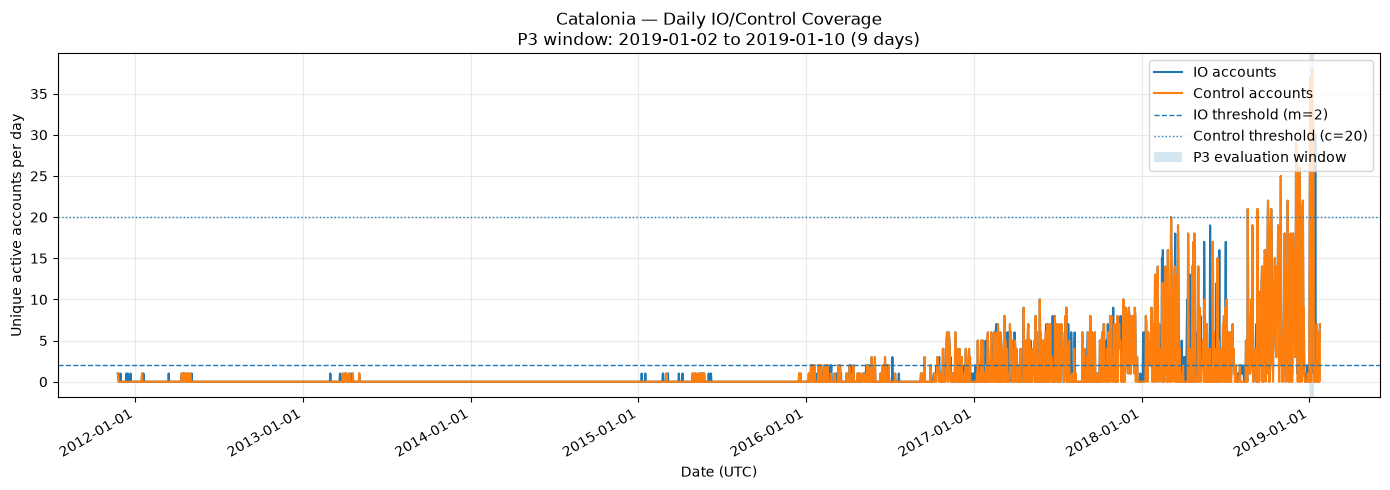

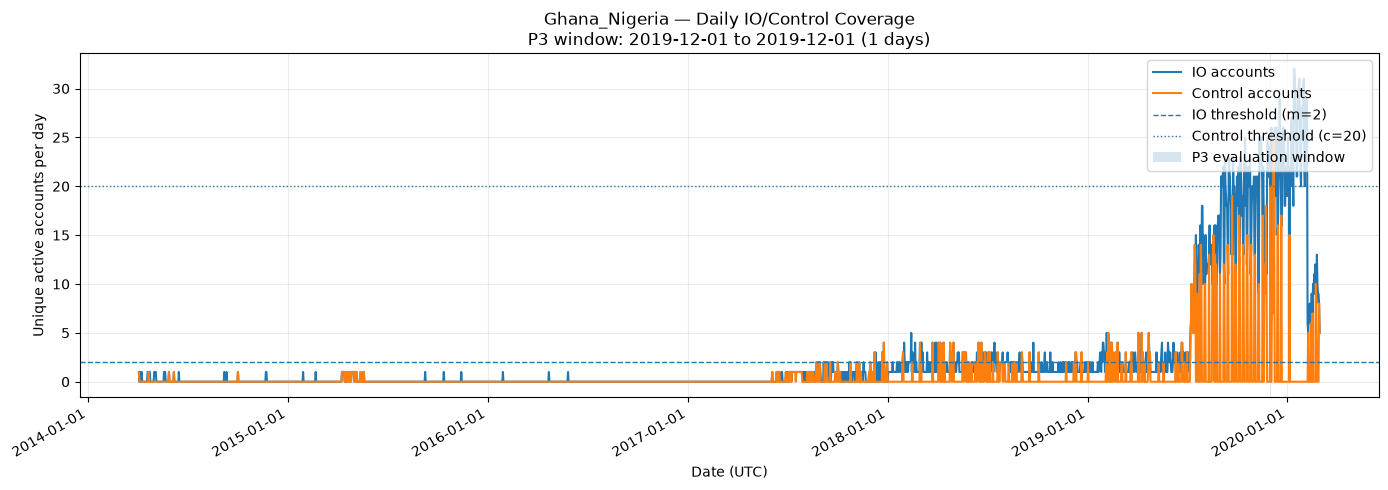

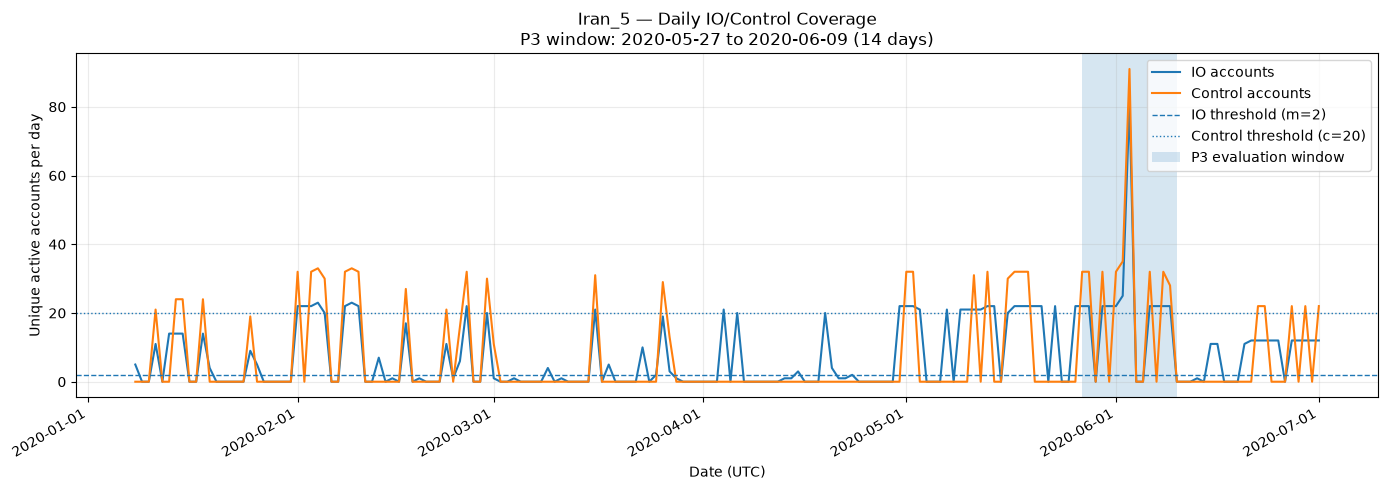

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

T8_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for campaign, cov in p2_coverage.items():

    # Bổ sung các ngày không có hoạt động bằng 0
    days = pd.date_range(start=cov.index.min(),end=cov.index.max(),freq="D")

    plot_df = cov.reindex(days, fill_value=0)

    fig, ax = plt.subplots(figsize=(14, 5))

    # Số tài khoản hoạt động mỗi ngày
    ax.plot( plot_df.index, plot_df["io"],label="IO accounts", linewidth=1.5)

    ax.plot(plot_df.index, plot_df["ctrl"],label="Control accounts", linewidth=1.5)

    # Ngưỡng phủ P2
    ax.axhline(M_IO, linestyle="--", linewidth=1, label=f"IO threshold (m={M_IO})")

    ax.axhline(C_CTRL, linestyle=":", linewidth=1,label=f"Control threshold (c={C_CTRL})")

    # Cửa sổ đánh giá P3
    window = p3_windows.get(campaign)

    if window is not None:
        start, end = window

        ax.axvspan(start, end + pd.Timedelta(days=1), alpha=0.18, label="P3 evaluation window")

        duration = (end - start).days + 1

        ax.set_title(f"{campaign} — Daily IO/Control Coverage\n" f"P3 window: {start:%Y-%m-%d} to " f"{end:%Y-%m-%d} ({duration} days)")
    else:
        ax.set_title(f"{campaign} — Daily IO/Control Coverage\n" "No eligible P3 window" )

    ax.set_xlabel("Date (UTC)")
    ax.set_ylabel("Unique active accounts per day")

    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=12))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d", tz=mdates.UTC))

    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")
    fig.autofmt_xdate()
    fig.tight_layout()

    output_path = (T8_OUTPUT_DIR / f"T8_daily_coverage_{campaign}.png")

    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)